<a href="https://colab.research.google.com/github/jawad-glitch/uncertainty-aware-drone-nav/blob/main/src/kf_imu.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [23]:
import os
from google.colab import drive

drive.mount('/content/drive')

REPO_URL = "https://github.com/jawad-glitch/uncertainty-aware-drone-nav.git"
REPO_DIR = "/content/drive/MyDrive/uncertainty-aware-drone-nav"

if not os.path.exists(REPO_DIR):
    !git clone {REPO_URL} {REPO_DIR}
else:
    print("Repo exists, pulling")
    %cd {REPO_DIR}
    !git pull

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Repo exists, pulling
/content/drive/MyDrive/uncertainty-aware-drone-nav
Already up to date.


In [24]:
!pip install filterpy

In [25]:
import sys
import numpy as np
import matplotlib.pyplot as plt
sys.path.append("/content/drive/MyDrive/uncertainty-aware-drone-nav/src")
import sensors
from filterpy.kalman import KalmanFilter

base = "/content/drive/MyDrive/uncertainty-aware-drone-nav/results/"
data = dict(np.load(base + "pid_flight.npz"))
meas = sensors.make_sensors(data, seed=0)
est_cv = np.load(base + "est_cv.npy")

dt = 1 / 48
n = len(data["time"])

In [26]:
Rm = sensors.rpy_to_rotmat(data["rpy"])
a_world = np.einsum("nij,nj->ni", Rm, meas["accel"]) + sensors.GRAVITY

# sanity check against the true acceleration
a_true = np.gradient(data["vel"], data["time"], axis=0)
print("accel error RMS (x, y):", np.sqrt(np.mean((a_world[:, :2] - a_true[:, :2])**2, axis=0)))
print("mean a_world z (should be ~0):", a_world[:, 2].mean())

accel error RMS (x, y): [0.08335036 0.05918591]
mean a_world z (should be ~0): 0.07698895588796523


In [27]:
kf = KalmanFilter(dim_x=4, dim_z=2)               # state [x, y, vx, vy]
kf.F = np.array([[1, 0, dt, 0],
                 [0, 1, 0, dt],
                 [0, 0, 1,  0],
                 [0, 0, 0,  1]])
B = np.array([[0.5*dt**2, 0],
              [0, 0.5*dt**2],
              [dt, 0],
              [0, dt]])                           # how acceleration changes the state
kf.H = np.array([[1, 0, 0, 0],
                 [0, 1, 0, 0]])
kf.R = np.eye(2) * 0.03**2                        # GPS noise, same as before
q = (0.05 * dt)**2                                # IMU accel noise (0.05) per step
kf.Q = np.diag([0, 0, q, q])
kf.x = np.array([meas["gps"][0, 0], meas["gps"][0, 1], 0, 0])
kf.P = np.diag([0.03**2, 0.03**2, 0.2**2, 0.2**2])

valid = meas["gps_valid"]
est_imu = np.zeros((n, 4))
sig_imu = np.zeros((n, 2))

for i in range(n):
    kf.predict(u=a_world[i, :2], B=B)             # IMU drives the prediction
    if valid[i]:
        kf.update(meas["gps"][i, :2])
    est_imu[i] = kf.x.ravel()
    sig_imu[i] = np.sqrt(np.diag(kf.P))[:2]

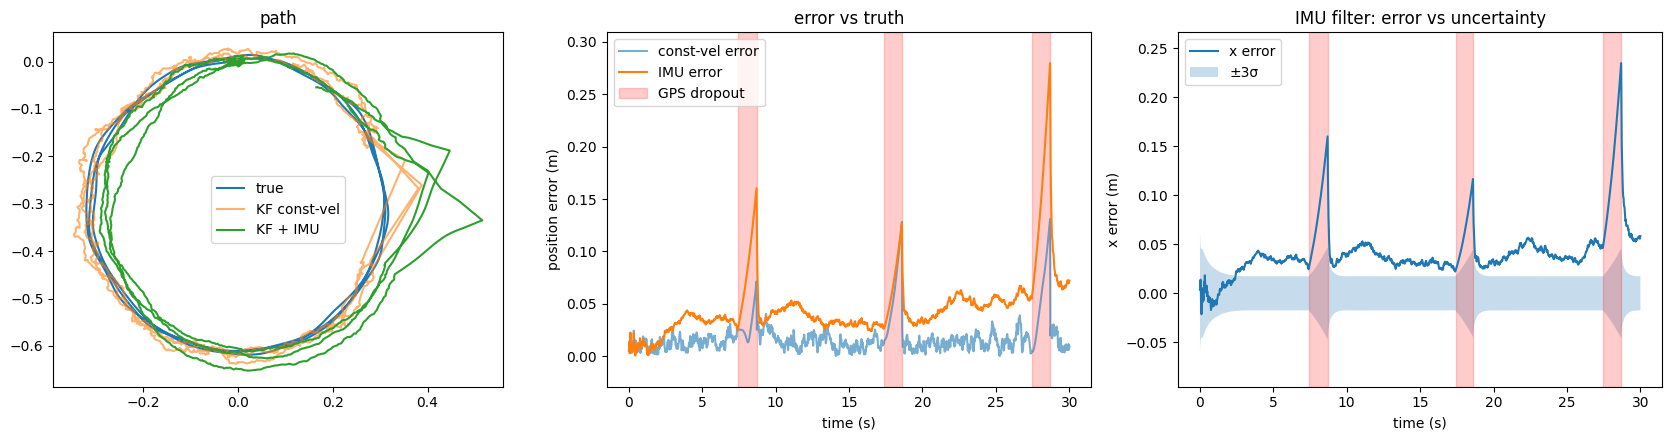

                    const-vel    IMU
all steps:          0.0254      0.0589
GPS steps:          0.0152      0.0437
inside dropout:     0.0594      0.1200


In [28]:
t = data["time"]
true_xy = data["pos"][:, :2]
err_cv = np.linalg.norm(est_cv[:, :2] - true_xy, axis=1)
err_imu = np.linalg.norm(est_imu[:, :2] - true_xy, axis=1)
err_x_imu = est_imu[:, 0] - true_xy[:, 0]

fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))

# 1) path
ax[0].plot(true_xy[:, 0], true_xy[:, 1], label="true")
ax[0].plot(est_cv[:, 0], est_cv[:, 1], alpha=0.6, label="KF const-vel")
ax[0].plot(est_imu[:, 0], est_imu[:, 1], label="KF + IMU")
ax[0].set_aspect("equal")
ax[0].legend()
ax[0].set_title("path")

# 2) error over time
ax[1].plot(t, err_cv, alpha=0.6, label="const-vel error")
ax[1].plot(t, err_imu, label="IMU error")
ax[1].fill_between(t, 0, 1, where=~valid, transform=ax[1].get_xaxis_transform(),
                   color="red", alpha=0.2, label="GPS dropout")
ax[1].set_xlabel("time (s)")
ax[1].set_ylabel("position error (m)")
ax[1].legend()
ax[1].set_title("error vs truth")

# 3) honesty check for the IMU filter
ax[2].plot(t, err_x_imu, label="x error")
ax[2].fill_between(t, -3 * sig_imu[:, 0], 3 * sig_imu[:, 0], alpha=0.25, label="±3σ")
ax[2].fill_between(t, 0, 1, where=~valid, transform=ax[2].get_xaxis_transform(),
                   color="red", alpha=0.2)
ax[2].set_xlabel("time (s)")
ax[2].set_ylabel("x error (m)")
ax[2].legend()
ax[2].set_title("IMU filter: error vs uncertainty")

plt.tight_layout()
plt.show()

def rmse(e, mask=None):
    e = e if mask is None else e[mask]
    return np.sqrt(np.mean(e**2))

print("                    const-vel    IMU")
print(f"all steps:          {rmse(err_cv):.4f}      {rmse(err_imu):.4f}")
print(f"GPS steps:          {rmse(err_cv, valid):.4f}      {rmse(err_imu, valid):.4f}")
print(f"inside dropout:     {rmse(err_cv, ~valid):.4f}      {rmse(err_imu, ~valid):.4f}")

In [29]:
def run_imu_bias_kf(a_world, gps, valid, q_vel=(0.05*dt)**2, q_bias=0.01**2*dt):
    # state [x, y, vx, vy, bx, by]; true accel = measured accel - bias
    kf = KalmanFilter(dim_x=6, dim_z=2)
    kf.F = np.array([[1, 0, dt, 0, -0.5*dt**2, 0],
                     [0, 1, 0, dt, 0, -0.5*dt**2],
                     [0, 0, 1,  0, -dt, 0],
                     [0, 0, 0,  1, 0, -dt],
                     [0, 0, 0,  0, 1, 0],
                     [0, 0, 0,  0, 0, 1]])
    B = np.array([[0.5*dt**2, 0],
                  [0, 0.5*dt**2],
                  [dt, 0],
                  [0, dt],
                  [0, 0],
                  [0, 0]])
    kf.H = np.array([[1, 0, 0, 0, 0, 0],
                     [0, 1, 0, 0, 0, 0]])
    kf.R = np.eye(2) * 0.03**2
    kf.Q = np.diag([0, 0, q_vel, q_vel, q_bias, q_bias])
    kf.x = np.array([gps[0, 0], gps[0, 1], 0, 0, 0, 0])
    kf.P = np.diag([0.03**2, 0.03**2, 0.2**2, 0.2**2, 0.05**2, 0.05**2])

    est = np.zeros((len(gps), 6))
    sig = np.zeros((len(gps), 6))
    for i in range(len(gps)):
        kf.predict(u=a_world[i, :2], B=B)
        if valid[i]:
            kf.update(gps[i, :2])
        est[i] = kf.x.ravel()
        sig[i] = np.sqrt(np.diag(kf.P))
    return est, sig

valid = meas["gps_valid"]
est_b, sig_b = run_imu_bias_kf(a_world, meas["gps"], valid)

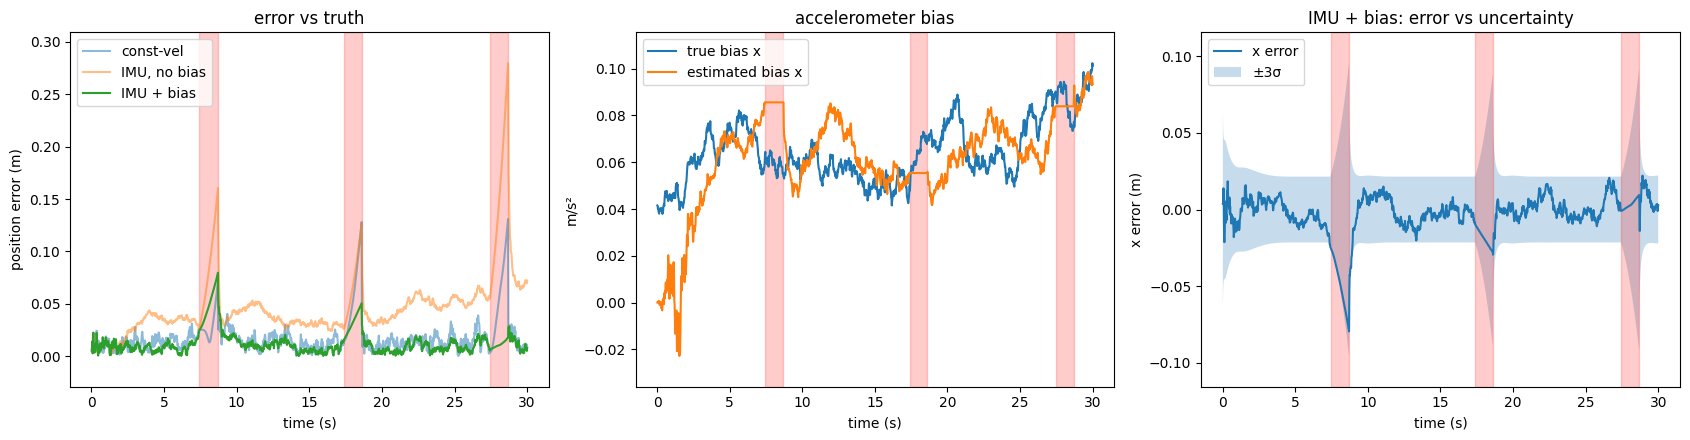

                 const-vel   IMU    IMU+bias
all steps:       0.0254     0.0589   0.0168
GPS steps:       0.0152     0.0437   0.0114
inside dropout:  0.0594     0.1200   0.0367


In [30]:
t = data["time"]
true_xy = data["pos"][:, :2]
err_b = np.linalg.norm(est_b[:, :2] - true_xy, axis=1)
err_x_b = est_b[:, 0] - true_xy[:, 0]

fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))

# 1) errors, all three filters
ax[0].plot(t, err_cv, alpha=0.5, label="const-vel")
ax[0].plot(t, err_imu, alpha=0.5, label="IMU, no bias")
ax[0].plot(t, err_b, label="IMU + bias")
ax[0].fill_between(t, 0, 1, where=~valid, transform=ax[0].get_xaxis_transform(),
                   color="red", alpha=0.2)
ax[0].set_xlabel("time (s)")
ax[0].set_ylabel("position error (m)")
ax[0].legend()
ax[0].set_title("error vs truth")

# 2) can the filter find the bias?
ax[1].plot(t, meas["accel_bias"][:, 0], label="true bias x")
ax[1].plot(t, est_b[:, 4], label="estimated bias x")
ax[1].fill_between(t, 0, 1, where=~valid, transform=ax[1].get_xaxis_transform(),
                   color="red", alpha=0.2)
ax[1].set_xlabel("time (s)")
ax[1].set_ylabel("m/s²")
ax[1].legend()
ax[1].set_title("accelerometer bias")

# 3) honesty check
ax[2].plot(t, err_x_b, label="x error")
ax[2].fill_between(t, -3 * sig_b[:, 0], 3 * sig_b[:, 0], alpha=0.25, label="±3σ")
ax[2].fill_between(t, 0, 1, where=~valid, transform=ax[2].get_xaxis_transform(),
                   color="red", alpha=0.2)
ax[2].set_xlabel("time (s)")
ax[2].set_ylabel("x error (m)")
ax[2].legend()
ax[2].set_title("IMU + bias: error vs uncertainty")

plt.tight_layout()
plt.show()

print("                 const-vel   IMU    IMU+bias")
print(f"all steps:       {rmse(err_cv):.4f}     {rmse(err_imu):.4f}   {rmse(err_b):.4f}")
print(f"GPS steps:       {rmse(err_cv, valid):.4f}     {rmse(err_imu, valid):.4f}   {rmse(err_b, valid):.4f}")
print(f"inside dropout:  {rmse(err_cv, ~valid):.4f}     {rmse(err_imu, ~valid):.4f}   {rmse(err_b, ~valid):.4f}")